In [ ]:
from scipy.stats import rankdata
import numpy as np

def avg_per_tf_spearman(grn1, grn2):
    """
    grn1, grn2: (G, T) matrices.

    Computes the mean Spearman correlation across TFs,
    ignoring genes where both GRNs have zero values.
    """

    tf_corrs = []

    for t in range(grn1.shape[1]):
        # Ignore genes where both GRNs have zero regulation
        eps = 1e-6

        mask = ~(
            (np.abs(grn1[:, t]) < eps) &
            (np.abs(grn2[:, t]) < eps)
        )

        x = grn1[mask, t]
        y = grn2[mask, t]

        # Need at least two non-zero/non-shared-zero entries
        if len(x) < 2:
            continue

        rx = rankdata(x)
        ry = rankdata(y)

        # Pearson correlation of ranks
        rx -= rx.mean()
        ry -= ry.mean()

        denom = np.sqrt(np.sum(rx**2) * np.sum(ry**2))

        if denom == 0:
            continue

        tf_corrs.append(np.sum(rx * ry) / denom)

    return np.mean(tf_corrs) if len(tf_corrs) > 0 else np.nan

Keeping 2995 shared genes
Keeping 277 shared TFs
Loaded weights: (1035, 4), A_dict: (4, 2995, 277)
Using 10 sampled cells out of 1035

=== Sampled Cells vs Population-Average GRN ===
Mean average-per-TF Spearman: 0.7946
Std: 0.1797
Min: 0.4384
Max: 0.9835

=== Sampled Cells vs CellOracle Global GRN ===
Mean average-per-TF Spearman: 0.2818
Std: 0.0644
Min: 0.1823
Max: 0.3540

=== Our Global GRN vs CellOracle Global GRN ===
Average-per-TF Spearman: 0.3475

=== Sampled Cell-Specific GRNs ===
Number of sampled pairwise comparisons: 45
Mean average-per-TF Spearman: 0.6239
Std: 0.2557
Min: 0.1926
Max: 0.9912

=== Module vs Module Average-per-TF Spearman ===
[[ 1.    -0.196  0.116  0.359]
 [-0.196  1.    -0.052 -0.354]
 [ 0.116 -0.052  1.    -0.017]
 [ 0.359 -0.354 -0.017  1.   ]]


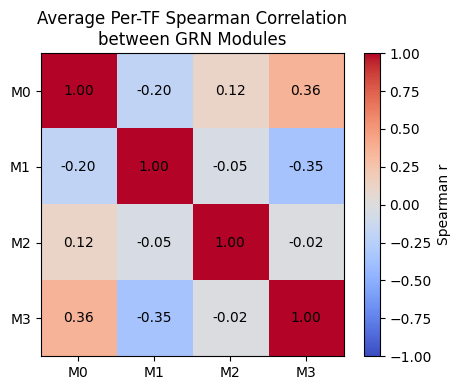

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from itertools import combinations
import pandas as pd

# ================================================================
# INSERT BASE DIRECTORY HERE
# ================================================================
BASE = "/home/elicanter/bert_grn_out_61_masking2"

# ----------------------------------------------------------------
# Load your method's outputs
# ----------------------------------------------------------------
weights = np.load(f"{BASE}/run0/mix_weights.npy")      # (cells, D)
A_dict  = np.load(f"{BASE}/run0/A_dict.npy")           # (D, G, T)
A_genes = np.load(f"{BASE}/run0/A_genes.npy", allow_pickle=True).astype(str)
A_tfs   = np.load(f"{BASE}/run0/A_tfs.npy", allow_pickle=True).astype(str)


# ----------------------------------------------------------------
# Restrict to genes/TFs present in CellOracle outputs
# ----------------------------------------------------------------
CO_BASE = "/home/elicanter/cell_oracle_run"

co_genes = np.load(
    f"{CO_BASE}/cell_oracle_global_A/A_genes.npy",
    allow_pickle=True
).astype(str)

co_tfs = np.load(
    f"{CO_BASE}/cell_oracle_global_A/A_tfs.npy",
    allow_pickle=True
).astype(str)


# ----------------------------------------------------------------
# Restrict to shared genes/TFs in identical order
# ----------------------------------------------------------------
co_A = np.load(f"{CO_BASE}/cell_oracle_global_A/A_celloracle.npy")  
co_A = np.abs(co_A.T)

common_genes = np.intersect1d(A_genes, co_genes)
common_tfs   = np.intersect1d(A_tfs, co_tfs)

print(f"Keeping {len(common_genes)} shared genes")
print(f"Keeping {len(common_tfs)} shared TFs")

a_gene_idx = pd.Index(A_genes).get_indexer(common_genes)
a_tf_idx   = pd.Index(A_tfs).get_indexer(common_tfs)

co_gene_idx = pd.Index(co_genes).get_indexer(common_genes)
co_tf_idx   = pd.Index(co_tfs).get_indexer(common_tfs)

# Restrict our dictionary
A_dict = A_dict[:, a_gene_idx][:, :, a_tf_idx]
A_genes = common_genes
A_tfs = common_tfs

# Restrict CellOracle global GRN
co_A = co_A[co_gene_idx][:, co_tf_idx]

assert co_A.shape == (len(A_genes), len(A_tfs))
assert A_dict.shape[1:] == co_A.shape


n_cells, D = weights.shape
G = len(A_genes)
T = len(A_tfs)

print(f"Loaded weights: {weights.shape}, A_dict: {A_dict.shape}")
assert A_dict.shape[0] == D


# ================================================================
# Helper: average per-TF Spearman correlation between two GRNs
# ================================================================
from scipy.stats import rankdata
"""
def avg_per_tf_spearman(grn1, grn2):
    
    #grn1, grn2: (G, T) matrices.

    #Computes the Spearman correlation of each TF column (across genes)
    #and returns the mean across TFs, ignoring constant columns.
    
    rx = rankdata(grn1, axis=0)
    ry = rankdata(grn2, axis=0)

    # Center each TF's ranks
    rx -= rx.mean(axis=0, keepdims=True)
    ry -= ry.mean(axis=0, keepdims=True)

    # Pearson correlation of the ranks
    num = np.sum(rx * ry, axis=0)
    denom = np.sqrt(np.sum(rx**2, axis=0) * np.sum(ry**2, axis=0))

    with np.errstate(divide="ignore", invalid="ignore"):
        corr = num / denom

    return np.nanmean(corr)
"""


# ================================================================
# A) Cell-specific GRNs (sampled)
# ================================================================

# Efficient representative sampling
N_SAMPLE = min(10, n_cells)
rng = np.random.default_rng(0)
sample_idx = rng.choice(n_cells, size=N_SAMPLE, replace=False)

print(f"Using {N_SAMPLE} sampled cells out of {n_cells}")

# Construct sampled cell-specific GRNs
# Result: (N_SAMPLE, G, T)
cell_grns = np.einsum("sd,dgt->sgt", weights[sample_idx], A_dict)

# ----------------------------------------------------------------
# Population-average GRN
# ----------------------------------------------------------------
mean_weights = weights.mean(axis=0)          # (D,)
global_grn = np.einsum("d,dgt->gt", mean_weights, A_dict)   # (G, T)

# ================================================================
# Cell-specific GRNs vs population-average GRN
# ================================================================
global_corrs = np.array([
    avg_per_tf_spearman(grn, global_grn)
    for grn in cell_grns
])

print("\n=== Sampled Cells vs Population-Average GRN ===")
print(f"Mean average-per-TF Spearman: {global_corrs.mean():.4f}")
print(f"Std: {global_corrs.std():.4f}")
print(f"Min: {global_corrs.min():.4f}")
print(f"Max: {global_corrs.max():.4f}")

# ================================================================
# Sampled Cells vs CellOracle Global GRN
# ================================================================
co_global_corrs = np.array([
    avg_per_tf_spearman(np.abs(grn), co_A)
    for grn in cell_grns
])

print("\n=== Sampled Cells vs CellOracle Global GRN ===")
print(f"Mean average-per-TF Spearman: {co_global_corrs.mean():.4f}")
print(f"Std: {co_global_corrs.std():.4f}")
print(f"Min: {co_global_corrs.min():.4f}")
print(f"Max: {co_global_corrs.max():.4f}")

# ================================================================
# Our Global GRN vs CellOracle Global GRN
# ================================================================
global_vs_co = avg_per_tf_spearman(np.abs(global_grn), co_A)

print("\n=== Our Global GRN vs CellOracle Global GRN ===")
print(f"Average-per-TF Spearman: {global_vs_co:.4f}")

# ================================================================
# Cell-specific GRNs vs each other (pairwise)
# ================================================================

pair_corrs = []
for i, j in combinations(range(N_SAMPLE), 2):
    c = avg_per_tf_spearman(cell_grns[i], cell_grns[j])
    if not np.isnan(c):
        pair_corrs.append(c)

pair_corrs = np.array(pair_corrs)

print("\n=== Sampled Cell-Specific GRNs ===")
print(f"Number of sampled pairwise comparisons: {len(pair_corrs)}")
print(f"Mean average-per-TF Spearman: {pair_corrs.mean():.4f}")
print(f"Std: {pair_corrs.std():.4f}")
print(f"Min: {pair_corrs.min():.4f}")
print(f"Max: {pair_corrs.max():.4f}")


# ================================================================
# B) GRN modules themselves (all D x D pairs)
# ================================================================
module_corr = np.eye(D)

for i in range(D):
    for j in range(i + 1, D):
        c = avg_per_tf_spearman(A_dict[i], A_dict[j])
        module_corr[i, j] = c
        module_corr[j, i] = c

print("\n=== Module vs Module Average-per-TF Spearman ===")
print(np.round(module_corr, 3))


# ================================================================
# Heatmap of module correlations
# ================================================================
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(module_corr, vmin=-1, vmax=1, cmap="coolwarm")

ax.set_xticks(range(D))
ax.set_yticks(range(D))
ax.set_xticklabels([f"M{i}" for i in range(D)])
ax.set_yticklabels([f"M{i}" for i in range(D)])

for i in range(D):
    for j in range(D):
        ax.text(j, i, f"{module_corr[i, j]:.2f}",
                ha="center", va="center", color="black")

ax.set_title("Average Per-TF Spearman Correlation\nbetween GRN Modules")
fig.colorbar(im, ax=ax, label="Spearman r")
plt.tight_layout()
plt.show()

In [18]:
# ================================================================
# Average and std of module weights across cells
# ================================================================

weight_mean = weights.mean(axis=0)   # (D,)
weight_std  = weights.std(axis=0)    # (D,)

print("Module weight statistics:")
for d in range(D):
    print(
        f"Module {d}: "
        f"mean = {weight_mean[d]:.4f}, "
        f"std = {weight_std[d]:.4f}"
    )

Module weight statistics:
Module 0: mean = 0.1702, std = 0.2435
Module 1: mean = 0.5082, std = 0.1727
Module 2: mean = 0.1108, std = 0.1343
Module 3: mean = 0.2108, std = 0.1247


In [40]:
print(avg_per_tf_spearman(np.abs(global_grn), co_A))

0.34751366458389715


In [22]:
from scipy.stats import rankdata

def avg_per_tf_spearman(grn1, grn2):
    """
    grn1, grn2: (G, T) matrices.

    Computes the mean Spearman correlation across TFs,
    ignoring genes where both GRNs have zero values.
    """

    tf_corrs = []

    for t in range(grn1.shape[1]):
        # Ignore genes where both GRNs have zero regulation
        eps = 1e-6

        mask = ~(
            (np.abs(grn1[:, t]) < eps) &
            (np.abs(grn2[:, t]) < eps)
        )

        x = grn1[mask, t]
        y = grn2[mask, t]

        # Need at least two non-zero/non-shared-zero entries
        if len(x) < 2:
            continue

        rx = rankdata(x)
        ry = rankdata(y)

        # Pearson correlation of ranks
        rx -= rx.mean()
        ry -= ry.mean()

        denom = np.sqrt(np.sum(rx**2) * np.sum(ry**2))

        if denom == 0:
            continue

        tf_corrs.append(np.sum(rx * ry) / denom)

    return np.mean(tf_corrs) if len(tf_corrs) > 0 else np.nan

print(avg_per_tf_spearman(np.abs(global_grn), co_A))

0.34751366458389715


In [21]:
print(np.mean(A_dict == 0))
print(np.mean(co_A == 0))

0.6734147767337861
0.6735654490335878


In [23]:
# ================================================================
# Jaccard overlap of TF target sets: model vs CellOracle
# ================================================================

def avg_tf_jaccard(grn1, grn2, threshold=0):
    """
    grn1, grn2: (G, T) matrices aligned by genes and TFs.

    For each TF:
        - define targets as entries > threshold
        - compute Jaccard overlap of target gene sets
    Returns mean Jaccard across TFs.
    """
    jaccards = []

    for t in range(grn1.shape[1]):
        targets1 = np.abs(grn1[:, t]) > threshold
        targets2 = np.abs(grn2[:, t]) > threshold

        intersection = np.sum(targets1 & targets2)
        union = np.sum(targets1 | targets2)

        # Ignore TFs with no predicted targets in either method
        if union > 0:
            jaccards.append(intersection / union)

    return np.mean(jaccards), np.array(jaccards)


# ---------------------------------------------------------------
# Compare global GRNs
# ---------------------------------------------------------------
mean_jaccard, tf_jaccards = avg_tf_jaccard(
    np.abs(global_grn),
    co_A,
    threshold=0
)

print("\n=== Global GRN vs CellOracle Jaccard ===")
print(f"Mean TF Jaccard: {mean_jaccard:.4f}")
print(f"Std across TFs: {tf_jaccards.std():.4f}")
print(f"Min: {tf_jaccards.min():.4f}")
print(f"Max: {tf_jaccards.max():.4f}")


=== Global GRN vs CellOracle Jaccard ===
Mean TF Jaccard: 0.9995
Std across TFs: 0.0007
Min: 0.9956
Max: 1.0000


In [37]:
def grn_jaccard(grn1, grn2, threshold=0):
    """
    Compute Jaccard similarity between two GRNs.

    grn1, grn2: (G, T) matrices with same ordering.
    threshold: minimum absolute value considered an edge.
    """

    edges1 = np.abs(grn1) > threshold
    edges2 = np.abs(grn2) > threshold

    intersection = np.sum(edges1 & edges2)
    union = np.sum(edges1 | edges2)

    return intersection / union if union > 0 else np.nan


jaccard = grn_jaccard(
    A_pred_shared,
    A_co_shared,
    threshold=0
)

print(f"GRN edge Jaccard: {jaccard:.4f}")

GRN edge Jaccard: 0.9995


Loaded 9 CellOracle cluster GRNs
Each cluster GRN shape: (2995, 277)

=== Our Global GRN vs CellOracle Clusters ===
Cluster 0: 0.2724
Cluster 1: 0.2892
Cluster 2: 0.3034
Cluster 3: 0.2829
Cluster 4: 0.3269
Cluster 5: 0.3072
Cluster 6: 0.3352
Cluster 7: 0.3125
Cluster 8: 0.3681

Mean: 0.3109
Std:  0.0277

=== CellOracle Cluster vs Cluster Average-per-TF Spearman ===
[[1.    0.365 0.314 0.266 0.3   0.285 0.365 0.321 0.337]
 [0.365 1.    0.369 0.344 0.316 0.357 0.361 0.337 0.387]
 [0.314 0.369 1.    0.319 0.352 0.333 0.385 0.295 0.399]
 [0.266 0.344 0.319 1.    0.305 0.349 0.319 0.324 0.411]
 [0.3   0.316 0.352 0.305 1.    0.282 0.435 0.253 0.395]
 [0.285 0.357 0.333 0.349 0.282 1.    0.305 0.378 0.376]
 [0.365 0.361 0.385 0.319 0.435 0.305 1.    0.307 0.418]
 [0.321 0.337 0.295 0.324 0.253 0.378 0.307 1.    0.34 ]
 [0.337 0.387 0.399 0.411 0.395 0.376 0.418 0.34  1.   ]]


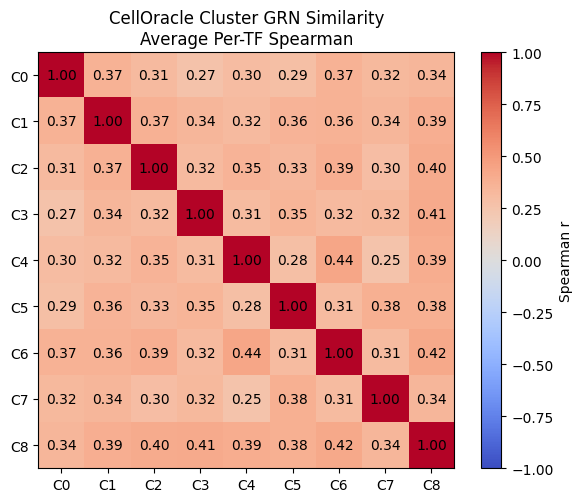

In [26]:
# ================================================================
# Load CellOracle cluster GRNs
# ================================================================
N_CLUSTERS = 9

cluster_As = [
    np.load(f"{CO_BASE}/A_clusters/A_cluster_{k}.npy")
    for k in range(N_CLUSTERS)
]

# CellOracle cluster GRNs are also TF x gene, so transpose
cluster_As = [np.abs(A.T) for A in cluster_As]

# Restrict to the same gene/TF universe
cluster_As = [
    A[co_gene_idx][:, co_tf_idx]
    for A in cluster_As
]

for k, A in enumerate(cluster_As):
    assert A.shape == (len(A_genes), len(A_tfs)), (
        f"Cluster {k} has shape {A.shape}, expected {(len(A_genes), len(A_tfs))}"
    )

print(f"Loaded {len(cluster_As)} CellOracle cluster GRNs")
print(f"Each cluster GRN shape: {cluster_As[0].shape}")


# ================================================================
# Compare CellOracle clusters to our global GRN
# ================================================================
cluster_vs_global = np.array([
    avg_per_tf_spearman(np.abs(global_grn), A)
    for A in cluster_As
])

print("\n=== Our Global GRN vs CellOracle Clusters ===")
for k, c in enumerate(cluster_vs_global):
    print(f"Cluster {k}: {c:.4f}")

print(f"\nMean: {cluster_vs_global.mean():.4f}")
print(f"Std:  {cluster_vs_global.std():.4f}")


# ================================================================
# CellOracle cluster vs cluster correlations
# ================================================================
cluster_corr = np.eye(N_CLUSTERS)

for i in range(N_CLUSTERS):
    for j in range(i + 1, N_CLUSTERS):
        c = avg_per_tf_spearman(
            cluster_As[i],
            cluster_As[j]
        )
        cluster_corr[i, j] = c
        cluster_corr[j, i] = c

print("\n=== CellOracle Cluster vs Cluster Average-per-TF Spearman ===")
print(np.round(cluster_corr, 3))


# ================================================================
# Heatmap
# ================================================================
fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(cluster_corr, vmin=-1, vmax=1, cmap="coolwarm")

ax.set_xticks(range(N_CLUSTERS))
ax.set_yticks(range(N_CLUSTERS))
ax.set_xticklabels([f"C{i}" for i in range(N_CLUSTERS)])
ax.set_yticklabels([f"C{i}" for i in range(N_CLUSTERS)])

for i in range(N_CLUSTERS):
    for j in range(N_CLUSTERS):
        ax.text(
            j, i,
            f"{cluster_corr[i,j]:.2f}",
            ha="center",
            va="center"
        )

ax.set_title(
    "CellOracle Cluster GRN Similarity\n"
    "Average Per-TF Spearman"
)

fig.colorbar(im, ax=ax, label="Spearman r")
plt.tight_layout()
plt.show()

In [ ]:
# ================================================================
# Sample cells from each cluster and compare to CellOracle cluster
# ================================================================

clusters_raw = np.load(
    "/home/elicanter/cell_oracle_run/clusters_raw.npy",
    allow_pickle=True
)
clusters_raw = clusters_raw.astype(int)

N_PER_CLUSTER = 5
rng = np.random.default_rng(0)

cluster_cell_corrs = []

for k in range(N_CLUSTERS):

    # Cells assigned to CellOracle cluster k
    cluster_cells = np.where(clusters_raw == k)[0]

    if len(cluster_cells) == 0:
        print(f"Cluster {k}: no cells")
        continue

    n_sample = min(N_PER_CLUSTER, len(cluster_cells))

    sampled_idx = rng.choice(
        cluster_cells,
        size=n_sample,
        replace=False
    )

    print(
        f"Cluster {k}: "
        f"{len(cluster_cells)} cells, "
        f"sampling {n_sample}"
    )

    # Construct GRNs directly for sampled cells
    sampled_grns = np.einsum(
        "sd,dgt->sgt",
        weights[sampled_idx],
        A_dict
    )

    # Compare each sampled cell to its CellOracle cluster GRN
    for i in range(n_sample):

        corr = avg_per_tf_spearman(
            np.abs(sampled_grns[i]),
            cluster_As[k]
        )

        cluster_cell_corrs.append(
            (k, sampled_idx[i], corr)
        )


# ================================================================
# Summary by cluster
# ================================================================

print("\n=== Sampled Cells vs Their CellOracle Cluster GRN ===")

for k in range(N_CLUSTERS):

    vals = np.array([
        corr
        for cluster, _, corr in cluster_cell_corrs
        if cluster == k
    ])

    if len(vals) > 0:
        print(
            f"Cluster {k}: "
            f"mean={vals.mean():.4f}, "
            f"std={vals.std():.4f}, "
            f"n={len(vals)}"
        )


all_corrs = np.array([x[2] for x in cluster_cell_corrs])

print("\nOverall:")
print(f"Mean: {all_corrs.mean():.4f}")
print(f"Std:  {all_corrs.std():.4f}")

Cluster 0: 310 cells, sampling 5
Cluster 1: 165 cells, sampling 5
Cluster 2: 141 cells, sampling 5
Cluster 3: 137 cells, sampling 5
Cluster 4: 115 cells, sampling 5
Cluster 5: 81 cells, sampling 5
Cluster 6: 57 cells, sampling 5
Cluster 7: 15 cells, sampling 5
Cluster 8: 14 cells, sampling 5

=== Sampled Cells vs Their CellOracle Cluster GRN ===
Cluster 0: mean=0.2694, std=0.0134, n=5
Cluster 1: mean=0.2459, std=0.0150, n=5
Cluster 2: mean=0.2446, std=0.0449, n=5
Cluster 3: mean=0.1383, std=0.0363, n=5
Cluster 4: mean=0.3129, std=0.0077, n=5
Cluster 5: mean=0.2554, std=0.0166, n=5
Cluster 6: mean=0.3090, std=0.0067, n=5
Cluster 7: mean=0.2043, std=0.0165, n=5
Cluster 8: mean=0.2803, std=0.0239, n=5

Overall:
Mean: 0.2511
Std:  0.0561


In [39]:
# ================================================================
# Sample cells from each cluster and compare to correct vs wrong
# CellOracle clusters
# ================================================================

N_PER_CLUSTER = 5
rng = np.random.default_rng(0)

cluster_cell_corrs = []
wrong_cluster_corrs = []

for k in range(N_CLUSTERS):

    cluster_cells = np.where(clusters_raw == k)[0]

    if len(cluster_cells) == 0:
        print(f"Cluster {k}: no cells")
        continue

    n_sample = min(N_PER_CLUSTER, len(cluster_cells))

    sampled_idx = rng.choice(
        cluster_cells,
        size=n_sample,
        replace=False
    )

    # Construct GRNs for sampled cells
    sampled_grns = np.einsum(
        "sd,dgt->sgt",
        weights[sampled_idx],
        A_dict
    )

    for i in range(n_sample):

        cell_grn = np.abs(sampled_grns[i])

        # -------------------------------
        # Correct cluster
        # -------------------------------
        corr_correct = avg_per_tf_spearman(
            cell_grn,
            np.abs(cluster_As[k])
        )

        cluster_cell_corrs.append(
            (k, sampled_idx[i], corr_correct)
        )

        # -------------------------------
        # Random wrong cluster
        # -------------------------------
        wrong_choices = [x for x in range(N_CLUSTERS) if x != k]
        wrong_k = rng.choice(wrong_choices)

        corr_wrong = avg_per_tf_spearman(
            cell_grn,
            cluster_As[wrong_k]
        )

        wrong_cluster_corrs.append(
            (k, wrong_k, sampled_idx[i], corr_wrong)
        )


# ================================================================
# Summaries
# ================================================================

correct_corrs = np.array([x[2] for x in cluster_cell_corrs])
wrong_corrs = np.array([x[3] for x in wrong_cluster_corrs])

print("\n=== Correct CellOracle Cluster ===")
print(f"Mean: {correct_corrs.mean():.4f}")
print(f"Std:  {correct_corrs.std():.4f}")

print("\n=== Random Wrong CellOracle Cluster ===")
print(f"Mean: {wrong_corrs.mean():.4f}")
print(f"Std:  {wrong_corrs.std():.4f}")

print("\nDifference:")
print(f"Correct - Wrong: {(correct_corrs.mean() - wrong_corrs.mean()):.4f}")


=== Correct CellOracle Cluster ===
Mean: 0.2502
Std:  0.0629

=== Random Wrong CellOracle Cluster ===
Mean: 0.2163
Std:  0.0819

Difference:
Correct - Wrong: 0.0339


Mean per-TF Spearman: 0.34751366458389715

--- Hub TF comparison ---
Hub TF agreement (Spearman): rho=0.8838


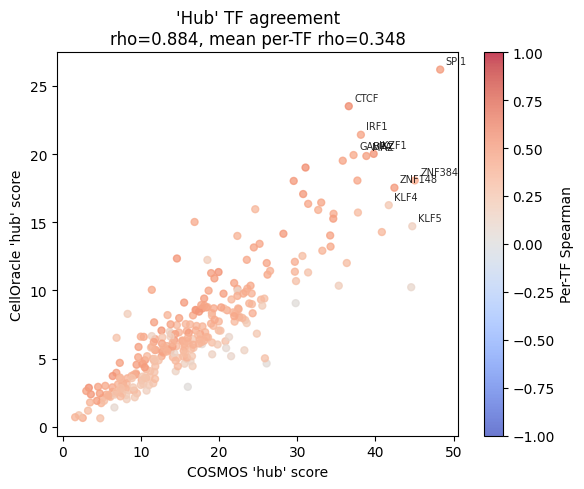

In [38]:
from scipy.stats import rankdata, spearmanr
import numpy as np
import matplotlib.pyplot as plt


# ================================================================
# Per-TF Spearman scores (one value per TF)
# ================================================================
def per_tf_spearman(grn1, grn2):
    """
    grn1, grn2: (G, T) matrices with same gene/TF ordering.

    Returns:
        tf_corrs: (T,) array
            Spearman correlation for each TF, computed across genes.
            Ignores genes where both GRNs are zero.
    """
    tf_corrs = []

    for t in range(grn1.shape[1]):

        # Remove shared-zero entries
        mask = ~(
            (np.abs(grn1[:, t]) == 0) &
            (np.abs(grn2[:, t]) == 0)
        )

        x = grn1[mask, t]
        y = grn2[mask, t]

        if len(x) < 2:
            tf_corrs.append(np.nan)
            continue

        rx = rankdata(x)
        ry = rankdata(y)

        rx -= rx.mean()
        ry -= ry.mean()

        denom = np.sqrt(np.sum(rx**2) * np.sum(ry**2))

        if denom == 0:
            tf_corrs.append(np.nan)
        else:
            tf_corrs.append(np.sum(rx * ry) / denom)

    return np.array(tf_corrs)



# ================================================================
# Compare two GRNs
# ================================================================

# Replace these two with whichever GRNs you want to compare
A_pred_shared = global_grn
A_co_shared = co_A

# Per-TF edge ranking agreement
tf_corrs = per_tf_spearman(
    np.abs(A_pred_shared),
    np.abs(A_co_shared)
)

print("Mean per-TF Spearman:",
      np.nanmean(tf_corrs))


# ================================================================
# Hub TF scores
# ================================================================

hub_pred = np.abs(A_pred_shared).sum(axis=0)
hub_co   = np.abs(A_co_shared).sum(axis=0)

hub_rho, _ = spearmanr(hub_pred, hub_co)

print("\n--- Hub TF comparison ---")
print(f"Hub TF agreement (Spearman): rho={hub_rho:.4f}")


# ================================================================
# Hub TF scatter colored by per-TF Spearman
# ================================================================

fig, ax = plt.subplots(figsize=(6, 5))

sc = ax.scatter(
    hub_pred,
    hub_co,
    c=tf_corrs,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    s=25,
    alpha=0.75
)

# Label top TFs by combined hub score
top10_idx = np.argsort(hub_pred + hub_co)[-10:]

for ti in top10_idx:
    ax.annotate(
        A_tfs[ti],
        (hub_pred[ti], hub_co[ti]),
        fontsize=7,
        alpha=0.85,
        xytext=(4, 4),
        textcoords="offset points"
    )

ax.set_xlabel("COSMOS 'hub' score")
ax.set_ylabel("CellOracle 'hub' score")
ax.set_title(
    f"'Hub' TF agreement\n"
    f"rho={hub_rho:.3f}, mean per-TF rho={np.nanmean(tf_corrs):.3f}"
)

fig.colorbar(
    sc,
    ax=ax,
    label="Per-TF Spearman"
)

plt.tight_layout()
plt.show()